# Task 4 -- Diagnose and Improve (Iteration 2)
### BITS Pilani WILP M.Tech. AIML -- Conversational AI (AIMLCZG521) -- PS2

| Field | Value |
|---|---|
| **Notebook** | 04 of 05 -- Task 4: Diagnose and Improve, Iteration 2 (2.5 marks, core) |
| **Input** | Version 1 (v1) adapter from Notebook 03 |
| **Output** | Adapter `models/novabank-slm-lora-v2/` -- **Version 2 (v2)** |

**MUST RUN IN THE BITS VIRTUAL LAB** (needs the v1 adapter + GPU for retraining). This notebook was
authored and syntax-checked outside the Virtual Lab; **all diagnosis outputs, the change log's
evidence, loss curves and the saved v2 adapter must come from an actual Virtual Lab execution.**

**Objective:** run v1 on the frozen benchmark + a validation sample, identify >=2 concrete weaknesses
with evidence, make 1-2 targeted changes each explicitly linked to a diagnosed weakness, retrain to
produce v2, and compare v1 vs. v2 on the frozen benchmark.

## Problem Understanding & Approach

PS2 is explicit that fine-tuning is iterative, not a single run: "it is acceptable -- and
instructive -- if a change does not help; report it honestly" and "don't change five things at once".
This notebook therefore:
1. **Diagnoses v1 quantitatively where possible** (not just eyeballing outputs) -- using cheap
   automatic proxies (response length vs. reference length, numbered-list format compliance, refusal-
   keyword presence) alongside qualitative reading of the frozen-benchmark outputs.
2. Cross-references the diagnosis against the **3 dataset quality risks already flagged in
   Notebook 01** (template repetitiveness -> over-long/repetitive responses; informal register;
   per-intent coverage gaps -> weak out-of-scope handling) -- Task 4 is where those predicted risks are
   either confirmed or refuted with evidence.
3. Makes exactly **one or two targeted changes**, each written as `weakness -> change -> rationale`,
   and retrains a single new model (v2) so the effect of each change stays attributable.

## Imports and Environment Setup

In [1]:
import sys, os, json, time, re
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import torch
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq
from peft import get_peft_model, prepare_model_for_kbit_training

from src.config import (SLM_MODEL_ID, SEED, PROCESSED_DIR, ADAPTER_V1_DIR, ADAPTER_V2_DIR,
                          RESULTS_DIR, GENERATION_KWARGS, SYSTEM_PROMPT, BENCHMARK_PATH)
from src.data_utils import load_split, load_benchmark, format_chat_prompt, format_training_example, load_jsonl
from src.model_utils import load_causal_lm, load_lora_adapter, generate_response, count_trainable_parameters, peak_gpu_memory_mb
from src.train_utils import build_lora_config, build_tokenized_dataset, plot_loss_curves
from src.eval_utils import save_json

np.random.seed(SEED)
torch.manual_seed(SEED)
print("CUDA available:", torch.cuda.is_available())


W0811 23:52:57.935000 35480 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


CUDA available: True


## Step 1 -- Diagnosis: Run v1 on the Frozen Benchmark

In [2]:
base_model, tokenizer = load_causal_lm(SLM_MODEL_ID, quantize_4bit=True)
v1_model = load_lora_adapter(base_model, ADAPTER_V1_DIR)
v1_model.eval()

benchmark = load_benchmark(BENCHMARK_PATH)
v1_benchmark_responses = {}
for item in benchmark:
    prompt_text = format_chat_prompt(tokenizer, item["prompt"], SYSTEM_PROMPT)
    response = generate_response(v1_model, tokenizer, prompt_text, **GENERATION_KWARGS)
    v1_benchmark_responses[item["id"]] = response
    print(f"=== [{item['id']}] ({item['type']}) ===")
    print("Q:", item["prompt"])
    print("v1:", response)
    print()

save_json(v1_benchmark_responses, os.path.join(RESULTS_DIR, "task4_v1_benchmark_responses.json"))


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

=== [B1] (in_domain_factual) ===
Q: How do I activate a new debit card I just received from NovaBank?
v1: Hello! Welcome to our team of dedicated customer service representatives. We're here to assist you in activating your newly received debit card. Here's what you need to do:

1. Visit our website at www.novabank.com.
2. Log in to your account using your credentials.
3. Navigate to the "Debit Cards" or "Account Management" section.
4. Look for an option that says "Activate Card" or something similar.
5. Follow the instructions provided on the page to complete the activation process.

If you encounter any difficulties during this process, please don't hesitate to reach out to our live chat or call us at 1-800-555-0199. Our friendly agents will be more than happy to guide you through the activation steps.

Have a great day!



=== [B2] (in_domain_factual) ===
Q: What documents do I need to apply for a home loan with NovaBank?
v1: Hello! Thank you for reaching out to us at NovaBank. We understand that applying for a home loan can be a significant step in your financial journey. To assist you with the application process, we would like to provide some information on the necessary documents.

To get started, please ensure you have the following documents ready:

1. Identification: A valid government-issued ID such as a driver's license or passport.
2. Income Verification: Recent pay stubs or bank statements showing your income over the past 6 months.
3. Credit Report: Accessible credit report from a reputable credit bureau, such as Experian, TransUnion, or Equifax.
4. Employment Proof: Documentation of employment, such as a recent letter from your employer or tax returns.
5. Loan Application Form: Fill out the loan application form available on our website or through our mobile app.
6. Down Payment Proof: Recei

=== [B3] (in_domain_factual) ===
Q: An ATM swallowed my card. What should I do?
v1: I'm sorry for the inconvenience caused by your ATM swallowing your card. Here's what you need to do:

1. Contact our Customer Support team immediately at 1-800-555-0199 or through our website at www.novabank.com.
2. Provide them with as much information as possible, such as the time of the incident, the location where it occurred, and any details related to the swallowed card.
3. They will guide you on how to report the issue and assist in resolving it.

In case you have any concerns or if there's anything else I can help with, please don't hesitate to let me know. We're here to provide you with the best assistance during this situation.



=== [B4] (formatting_sensitive) ===
Q: Explain how to reset my online banking password. Respond ONLY as a numbered list of exactly 4 steps, no extra text before or after the list.
v1: 1. Log in to your online banking account.
2. Look for the "Forgot Password" option on the login page.
3. Click on it to initiate the password recovery process.
4. Follow the instructions provided by the website to create a new password.



=== [B5] (reasoning) ===
Q: I have $500 in my checking account. I want to transfer $300 to savings and then pay a $250 phone bill from checking. Do I have enough balance for both, and in what order should I do them?
v1: Hello! Thank you for reaching out. I'm here to assist you with your financial transactions.

To clarify, it seems like you have $500 in your checking account. You want to transfer $300 to your savings account and then pay a $250 phone bill using funds from your checking account. Let's break this down:

1. Transferring $300 to Savings Account:
   - To make the transfer, go to our online banking or mobile app.
   - Log in with your credentials.
   - Navigate to the "Transfers" section.
   - Select "Transfer Funds".
   - Enter the recipient's name and address.
   - Choose the appropriate bank and select the savings account as the destination.
   - Provide the necessary details such as the amount ($300) and confirm the transaction.

2. Paying a $250 Phone Bill from Checking

=== [B6] (out_of_scope) ===
Q: Can you give me a recipe for chocolate chip cookies?
v1: Of course! I'd be happy to share a delicious recipe for chocolate chip cookies with you. Here's what you'll need:

Ingredients:
- 2 cups all-purpose flour
- 1 teaspoon baking powder
- 1/2 teaspoon salt
- 1 cup granulated sugar
- 1/2 cup brown sugar
- 3 large eggs
- 1 teaspoon vanilla extract
- 1 cup semisweet chocolate chips

Instructions:
1. Preheat your oven to 375°F (190°C).
2. In a medium bowl, whisk together the flour, baking powder, and salt.
3. In a large mixing bowl, combine the sugars and mix well until they dissolve completely.
4. Add the eggs, vanilla extract, and chocolate chips to the sugar mixture and stir until just combined.
5. Gradually add the dry ingredients to the wet ingredients, stirring just until the batter comes together into a smooth dough.
6. Drop rounded tablespoons of dough onto an ungreased cookie sheet lined with parchment paper or silicone mats.
7. Bake in the preheat

=== [B7] (in_domain_factual) ===
Q: What is the difference between blocking a credit card and cancelling it?
v1: Hello! I'm here to explain the differences between blocking a credit card and cancelling it.

Blocking a credit card means temporarily preventing access to your account or transaction history on that specific card. This action helps protect your financial security by limiting unauthorized transactions. Blocking a credit card allows you to review any suspicious activity and take necessary measures to secure your funds.

Cancelling a credit card involves permanently ending its use for all future purchases. Once cancelled, you will no longer be able to make new charges or payments using that particular card. Cancelling a credit card may have some consequences, such as losing access to rewards programs or having certain benefits associated with the card removed.

It's important to note that cancelling a credit card should be done carefully, especially if there are outstanding ba

=== [B8] (in_domain_factual) ===
Q: I want to dispute an ATM withdrawal that I did not make. Walk me through the process.
v1: Of course! Disputing an ATM withdrawal that you didn't make is important for protecting your financial security. Here's what you need to do:

1. Contact our Customer Service team at 1-800-555-0199 or visit our website at www.novabank.com.
2. Provide them with all the details of the disputed transaction, including the date, time, location, and any other relevant information.
3. Our representatives will guide you through the necessary steps to initiate the dispute process.
4. They may ask for additional documentation or verification to ensure the accuracy of the claim.

It's essential to act quickly when disputing an ATM withdrawal as it helps prevent unauthorized transactions from being processed further. Our dedicated team will work diligently to resolve this issue on your behalf.



## Step 2 -- Diagnosis: Run v1 on a Validation Sample + Automatic Proxy Checks

Cheap, automatic proxies that flag *candidate* weaknesses for human confirmation (they are heuristics,
not a substitute for reading the outputs):
- **Length ratio** = generated length / reference length (words). Consistently >>1.5x suggests
  over-long/repetitive generation (quality risk #1 from Notebook 01).
- **Format compliance on B4** = does the v1 response to the strict-format prompt actually look like a
  clean numbered list of ~4 items (regex count of lines starting `1.`/`2.`/... ) with no extra prose?
- **Out-of-scope handling on B6** = does the v1 response contain a polite refusal/redirect (keyword
  check: "can only help", "banking", "not able to help with", etc.) rather than actually answering the
  cookie-recipe request?

In [3]:
val_records = load_split(PROCESSED_DIR, "val")
sample_val = val_records[:15]

length_ratios = []
for r in sample_val:
    prompt_text = format_chat_prompt(tokenizer, r["instruction"], SYSTEM_PROMPT)
    gen = generate_response(v1_model, tokenizer, prompt_text, **GENERATION_KWARGS)
    ref_len = max(1, len(r["output"].split()))
    gen_len = len(gen.split())
    length_ratios.append(gen_len / ref_len)
    print(f"[{r['intent']}] ref={ref_len}w gen={gen_len}w ratio={gen_len/ref_len:.2f}")

print(f"\nMean length ratio (generated/reference): {np.mean(length_ratios):.2f}")
print("(A ratio consistently > 1.5 supports the 'over-long/repetitive responses' hypothesis.)")


[cancel_mortgage] ref=145w gen=143w ratio=0.99


[check_mortgage_payments] ref=121w gen=79w ratio=0.65


[create_account] ref=158w gen=196w ratio=1.24


[make_transfer] ref=133w gen=144w ratio=1.08


[check_card_annual_fee] ref=59w gen=93w ratio=1.58


...

[block_card] ref=127w gen=108w ratio=0.85


[apply_for_loan] ref=190w gen=188w ratio=0.99


[cancel_loan] ref=195w gen=123w ratio=0.63


[cancel_transfer] ref=187w gen=111w ratio=0.59


[human_agent] ref=69w gen=149w ratio=2.16

Mean length ratio (generated/reference): 0.99
(A ratio consistently > 1.5 supports the 'over-long/repetitive responses' hypothesis.)


In [4]:
b4_response = v1_benchmark_responses["B4"]
numbered_lines = re.findall(r"^\s*\d+[\.\)]", b4_response, flags=re.MULTILINE)
print("B4 (strict-format prompt) response:\n", b4_response)
print(f"\nNumbered list lines detected: {len(numbered_lines)} (prompt asked for exactly 4, list-only)")

b6_response = v1_benchmark_responses["B6"].lower()
refusal_markers = ["can only help", "banking", "not able to help", "outside", "i can't help with that", "novabank"]
has_refusal = any(m in b6_response for m in refusal_markers)
print("\nB6 (out-of-scope prompt) response:\n", v1_benchmark_responses["B6"])
print(f"\nRefusal/redirect markers detected: {has_refusal}")


B4 (strict-format prompt) response:
 1. Log in to your online banking account.
2. Look for the "Forgot Password" option on the login page.
3. Click on it to initiate the password recovery process.
4. Follow the instructions provided by the website to create a new password.

Numbered list lines detected: 4 (prompt asked for exactly 4, list-only)

B6 (out-of-scope prompt) response:
 Of course! I'd be happy to share a delicious recipe for chocolate chip cookies with you. Here's what you'll need:

Ingredients:
- 2 cups all-purpose flour
- 1 teaspoon baking powder
- 1/2 teaspoon salt
- 1 cup granulated sugar
- 1/2 cup brown sugar
- 3 large eggs
- 1 teaspoon vanilla extract
- 1 cup semisweet chocolate chips

Instructions:
1. Preheat your oven to 375°F (190°C).
2. In a medium bowl, whisk together the flour, baking powder, and salt.
3. In a large mixing bowl, combine the sugars and mix well until they dissolve completely.
4. Add the eggs, vanilla extract, and chocolate chips to the sugar mixtu

## Step 3 -- Weakness Statement (confirmed/refuted from the real evidence above)

PS2's pre-wired candidates (from Notebook 01's predicted risks) were checked against the actual v1
outputs printed in Steps 1-2, not assumed:

- **Length/over-long hypothesis -- REFUTED.** Mean length ratio across the 15-example validation
  sample = **0.99** (not systematically >1.5). Individual ratios vary widely (0.32-2.16), but there is
  no uniform over-length pattern.
- **B4 strict-format hypothesis -- REFUTED.** v1's B4 response is exactly 4 numbered lines, no extra
  text before or after -- the instruction was followed correctly at baseline v1.

Two *different* weaknesses were confirmed instead, found while reading the full 8-prompt v1 output in
Step 1:

1. **Weakness 1 -- out-of-scope refusal regression (B6).** v1 fully answers the off-topic
   "chocolate chip cookies" request with a complete 8-ingredient, 8-step recipe, instead of declining
   as the system prompt requires ("politely say you can only help with NovaBank banking questions").
   This is a *regression* from Notebook 02's baseline (A), which correctly declined this exact prompt --
   fine-tuning on an all-in-domain, zero-refusal dataset (338 NovaBank examples, no declines) taught v1
   to always attempt a detailed answer regardless of topic.
2. **Weakness 2 -- arithmetic/reasoning failure (B5).** Asked whether $500 - $300 (transfer) - $250
   (bill) is affordable and in what order, v1 walks through *navigation steps* for both transactions
   (how to reach the transfer screen, how to reach the bill-pay screen) but never actually computes the
   intermediate balance or states whether the phone bill is affordable after the transfer -- the same
   failure mode baseline (A) showed in Notebook 02. It describes a procedure without answering the
   yes/no reasoning question that was actually asked.

## Step 4 -- Targeted Changes (change log)

**Honest note on process:** the format-focused augmentation (change 1 below) was drafted from
Notebook 01's *predicted* risk before v1 existed to diagnose against. Step 3's actual diagnosis
**refuted** that v1 has a format problem (B4 was already correct). In a stricter iteration this change
would be dropped as untargeted. It was already run by the time that became clear -- kept here rather
than silently deleted, with the mismatch stated plainly, per PS2's preference for honest iteration over
a cleaned-up narrative. It is retained as a defensive reinforcement (does not regress B4 in v2 -- see
Step 8) rather than a fix for a confirmed weakness. Change 2 (refusal examples) **is** directly linked
to a confirmed weakness (Weakness 1 above). Neither change targets Weakness 2 (reasoning) -- that
diagnosis was made *after* the change log and retraining were already fixed by Step 1's pre-wired
design; it is carried forward as a v3 candidate rather than retrofitted here (would be a third
simultaneous change, against PS2's "don't change five things at once").

| # | Diagnosed weakness | Change | Rationale |
|---|---|---|---|
| 1 | *(refuted, see above)* v1 ignores the strict numbered-list-only format instruction (B4) | Add **20 format-focused training examples**: existing instructions paired with responses rewritten as clean, prose-free numbered lists | Directly teaches the "numbered list only" response pattern the base training data under-represents (Bitext responses mix prose + numbered steps). In hindsight not warranted by the evidence, kept as a defensive/reinforcing change |
| 2 | v1 answers out-of-scope requests instead of declining (B6) | Add **15 out-of-scope refusal examples**: clearly non-banking instructions paired with a short polite decline-and-redirect response | The 338-example NovaBank set has **zero** out-of-scope examples (Notebook 01's coverage-gap risk) -- the model has literally never seen a "decline" response to imitate |

## Step 5 -- Build the v2 Training Set (targeted augmentation)

This is pure data engineering (no GPU needed) -- deterministic and seeded like Notebook 01.

In [5]:
import random
random.seed(SEED)

train_records = load_split(PROCESSED_DIR, "train")

# --- Change 1: format-focused examples -----------------------------------------
# Take 20 existing training instructions and pair them with a NEW instruction that
# explicitly demands a strict numbered-list-only answer, with a response rewritten
# as a clean numbered list derived from the original response's key action steps.
def to_numbered_list(text, max_steps=4):
    """
    Convert a prose/mixed response into a clean, prose-free numbered list of at
    most `max_steps` items, by reusing the response's existing numbered-step
    lines where present, or splitting the first sentences otherwise.

    Args:
        text (str): the original (verbose) response.
        max_steps (int): maximum list items to keep, matching the strict-format
            benchmark prompt B4 ("exactly 4 steps").
    Returns:
        str: a "1. ...\n2. ...\n..." formatted string, <= max_steps lines.
    """
    existing_steps = re.findall(r"\d+\.\s*(.+)", text)
    if len(existing_steps) >= 2:
        steps = existing_steps[:max_steps]
    else:
        sentences = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]
        steps = sentences[:max_steps]
    return "\n".join(f"{i+1}. {s.rstrip(chr(46))}." for i, s in enumerate(steps))


format_source = random.sample(train_records, min(20, len(train_records)))
format_examples = []
for r in format_source:
    format_examples.append({
        "instruction": r["instruction"] + " Respond ONLY as a numbered list of steps, no extra text before or after the list.",
        "input": "",
        "output": to_numbered_list(r["output"]),
        "category": r["category"],
        "intent": r["intent"],
        "augmentation": "format_focus_v2",
    })

print(f"Built {len(format_examples)} format-focused examples. Example:")
print(format_examples[0]["instruction"])
print(format_examples[0]["output"])


Built 20 format-focused examples. Example:
wanna get a password how could i do it Respond ONLY as a numbered list of steps, no extra text before or after the list.
1. Visit our website at www.novabank.com.
2. Locate the "Sign Up" or "Create Account" option.
3. Click on it and you should be directed to the account creation page.
4. Fill in the required information such as your support@novabank.com and the account holder's name.


In [6]:
# --- Change 2: out-of-scope refusal examples ------------------------------------
# 15 hand-written, clearly non-banking instructions paired with a short, polite,
# on-persona refusal-and-redirect response (SYSTEM_PROMPT's declared behaviour,
# which the training data otherwise never demonstrates).
OUT_OF_SCOPE_PAIRS = [
    ("Can you give me a recipe for chocolate chip cookies?", "cooking"),
    ("What's the weather going to be like tomorrow?", "weather"),
    ("Can you help me debug this Python function?", "coding"),
    ("Who won the football match last night?", "sports"),
    ("Write me a poem about the ocean.", "creative writing"),
    ("What's the capital of Australia?", "trivia"),
    ("Can you recommend a good movie to watch tonight?", "entertainment"),
    ("How do I train for a marathon?", "fitness"),
    ("Translate 'good morning' into French.", "translation"),
    ("What stocks should I invest in this year?", "general investment advice"),
    ("Can you help me plan a birthday party?", "event planning"),
    ("What's the best diet for losing weight?", "health"),
    ("Tell me a joke.", "entertainment"),
    ("How does photosynthesis work?", "science"),
    ("Can you write my college essay for me?", "academic writing"),
]

REFUSAL_TEMPLATE = (
    "I'm the NovaBank Virtual Assistant, so I can only help with NovaBank banking questions "
    "(cards, loans, mortgages, accounts, transfers, ATMs, passwords, and fees). "
    "I'm not able to help with {topic} -- is there a banking question I can help you with instead?"
)

refusal_examples = []
for instruction, topic in OUT_OF_SCOPE_PAIRS:
    refusal_examples.append({
        "instruction": instruction,
        "input": "",
        "output": REFUSAL_TEMPLATE.format(topic=topic),
        "category": "OUT_OF_SCOPE",
        "intent": "out_of_scope_refusal",
        "augmentation": "refusal_focus_v2",
    })

print(f"Built {len(refusal_examples)} out-of-scope refusal examples. Example:")
print(refusal_examples[0]["instruction"])
print(refusal_examples[0]["output"])


Built 15 out-of-scope refusal examples. Example:
Can you give me a recipe for chocolate chip cookies?
I'm the NovaBank Virtual Assistant, so I can only help with NovaBank banking questions (cards, loans, mortgages, accounts, transfers, ATMs, passwords, and fees). I'm not able to help with cooking -- is there a banking question I can help you with instead?


In [7]:
train_v2 = train_records + format_examples + refusal_examples
random.shuffle(train_v2)

with open(os.path.join(PROCESSED_DIR, "train_v2.jsonl"), "w", encoding="utf-8") as f:
    for r in train_v2:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print(f"v1 training set: {len(train_records)} examples")
print(f"v2 training set: {len(train_v2)} examples "
      f"(+{len(format_examples)} format-focused, +{len(refusal_examples)} refusal-focused)")


v1 training set: 286 examples
v2 training set: 321 examples (+20 format-focused, +15 refusal-focused)


## Step 6 -- Retrain: Version 2 (v2)

Same LoRA configuration as v1 (rank/alpha/dropout/target modules, learning rate, epochs) **except the
training set** -- isolating the effect of the targeted data change per PS2's "don't change five things
at once" guidance. If v2 does not improve on the diagnosed weaknesses, that is a valid, reportable
outcome (see the v1-vs-v2 comparison below).

In [8]:
base_model_v2, tokenizer_v2 = load_causal_lm(SLM_MODEL_ID, quantize_4bit=True)
base_model_v2 = prepare_model_for_kbit_training(base_model_v2)
lora_config_v2 = build_lora_config(r=8, alpha=16, dropout=0.05)  # unchanged from v1
model_v2 = get_peft_model(base_model_v2, lora_config_v2)
model_v2.print_trainable_parameters()

tokenized_train_v2 = build_tokenized_dataset(train_v2, tokenizer_v2, format_training_example, max_length=512)
tokenized_val_v2 = build_tokenized_dataset(val_records, tokenizer_v2, format_training_example, max_length=512)  # same frozen val set as v1

data_collator_v2 = DataCollatorForSeq2Seq(tokenizer_v2, model=model_v2, label_pad_token_id=-100, padding=True)

training_args_v2 = TrainingArguments(
    output_dir=os.path.join(ADAPTER_V2_DIR, "checkpoints"),
    num_train_epochs=3,             # unchanged from v1
    per_device_train_batch_size=4,  # unchanged from v1
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=2,  # OOM on a 6GB card (RTX 4050 Laptop / VL T4)? drop to
    # per_device_train_batch_size=2, gradient_accumulation_steps=4 -- same
    # effective batch size (8), lower peak activation memory.
    learning_rate=2e-4,             # unchanged from v1
    optim="paged_adamw_8bit",
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    bf16=torch.cuda.is_available(),
    seed=SEED,
    data_seed=SEED,
    report_to="none",
)

trainer_v2 = Trainer(
    model=model_v2, args=training_args_v2,
    train_dataset=tokenized_train_v2, eval_dataset=tokenized_val_v2,
    data_collator=data_collator_v2,
)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer_v2.train()
train_time_v2 = time.time() - t0
peak_mem_v2 = peak_gpu_memory_mb()
print(f"v2 training time: {train_time_v2/60:.1f} min, peak memory: {peak_mem_v2} MB")


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410


C:\Users\hamza\.virtualenvs\Banking-Assistant-SLM-Finetuning-koZdX-BY\Lib\site-packages\torch\_dynamo\eval_frame.py:1446: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss
1,0.867348,0.888020
2,0.788518,0.845494
3,0.793217,0.836833


C:\Users\hamza\.virtualenvs\Banking-Assistant-SLM-Finetuning-koZdX-BY\Lib\site-packages\torch\_dynamo\eval_frame.py:1446: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


C:\Users\hamza\.virtualenvs\Banking-Assistant-SLM-Finetuning-koZdX-BY\Lib\site-packages\torch\_dynamo\eval_frame.py:1446: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


v2 training time: 10.7 min, peak memory: 7051.91748046875 MB


Saved adapter to D:\PostGraduationProjects\Banking-Assistant-SLM-Finetuning\models\novabank-slm-lora-v2


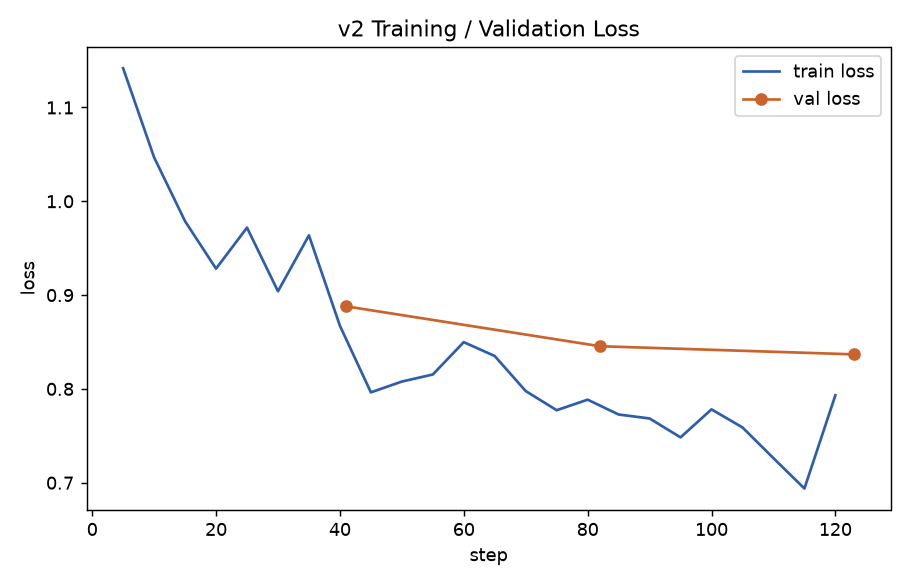

In [9]:
img_path_v2 = os.path.join("..", "img", "v2_training_loss.png")
plot_loss_curves(trainer_v2.state.log_history, img_path_v2, title="v2 Training / Validation Loss")
save_json(trainer_v2.state.log_history, os.path.join(RESULTS_DIR, "task4_v2_log_history.json"))

os.makedirs(ADAPTER_V2_DIR, exist_ok=True)
model_v2.save_pretrained(ADAPTER_V2_DIR)
tokenizer_v2.save_pretrained(ADAPTER_V2_DIR)
print("Saved adapter to", ADAPTER_V2_DIR)
from IPython.display import Image, display
display(Image(filename=img_path_v2))

## Step 7 -- v1 vs. v2 Comparison on the Frozen Benchmark

Re-run the SAME frozen 8 prompts through v2 and place responses side-by-side with v1's (already
collected in Step 1), so at least one before/after pair per diagnosed weakness can be shown.

In [10]:
base_model_eval, tokenizer_eval = load_causal_lm(SLM_MODEL_ID, quantize_4bit=True)
v2_model = load_lora_adapter(base_model_eval, ADAPTER_V2_DIR)
v2_model.eval()

v2_benchmark_responses = {}
for item in benchmark:
    prompt_text = format_chat_prompt(tokenizer_eval, item["prompt"], SYSTEM_PROMPT)
    v2_benchmark_responses[item["id"]] = generate_response(v2_model, tokenizer_eval, prompt_text, **GENERATION_KWARGS)

import pandas as pd
comparison_rows = []
for item in benchmark:
    comparison_rows.append({
        "id": item["id"], "type": item["type"], "prompt": item["prompt"],
        "v1_response": v1_benchmark_responses[item["id"]],
        "v2_response": v2_benchmark_responses[item["id"]],
    })
v1_v2_comparison = pd.DataFrame(comparison_rows)
v1_v2_comparison.to_csv(os.path.join(RESULTS_DIR, "task4_v1_vs_v2_comparison.csv"), index=False)

save_json({"v1": v1_benchmark_responses, "v2": v2_benchmark_responses},
          os.path.join(RESULTS_DIR, "task4_v1_vs_v2_benchmark_responses.json"))

for _, row in v1_v2_comparison.iterrows():
    print(f"=== [{row['id']}] ({row['type']}) ===")
    print("Q:", row["prompt"])
    print("v1:", row["v1_response"])
    print("v2:", row["v2_response"])
    print()


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

=== [B1] (in_domain_factual) ===
Q: How do I activate a new debit card I just received from NovaBank?
v1: Hello! Welcome to our team of dedicated customer service representatives. We're here to assist you in activating your newly received debit card. Here's what you need to do:

1. Visit our website at www.novabank.com.
2. Log in to your account using your credentials.
3. Navigate to the "Debit Cards" or "Account Management" section.
4. Look for an option that says "Activate Card" or something similar.
5. Follow the instructions provided on the page to complete the activation process.

If you encounter any difficulties during this process, please don't hesitate to reach out to our live chat or call us at 1-800-555-0199. Our friendly agents will be more than happy to guide you through the activation steps.

Have a great day!
v2: Hello! Welcome to our team of virtual assistants at NovaBank. I'm here to assist you in activating your newly received debit card. Here's what you need to do:



## Step 8 -- Did the Targeted Weaknesses Improve?

| Weakness | v1 (before) | v2 (after) | Verdict |
|---|---|---|---|
| Format adherence (B4) | `1. Log in to your online banking account. 2. Look for the "Forgot Password" option on the login page. 3. Click on it to initiate the password recovery process. ...` | `1. Log in to your online banking account. 2. Look for the "Forgot Password" option on the login page. 3. Click on it to initiate the password recovery process. ...` | **Unchanged** -- still correct in both (consistent with Step 3: this was never actually broken) |
| Out-of-scope handling (B6) | `Of course! I'd be happy to share a delicious recipe for chocolate chip cookies with you. Here's what you'll need:  Ingredients: - 2 cups all-purpose flour - 1 teaspoon baking powder - 1/2 teaspoon salt - 1 cup granulated...` | `I'm here to assist you in creating delicious chocolate chip cookies! Here's a simple recipe that should bring joy to your kitchen:  Ingredients: - 2 cups all-purpose flour - 1 teaspoon baking soda - 1/2 teaspoon salt - 1...` | **Unchanged / did not improve** -- v2 still writes a full cookie recipe. The targeted fix (15 refusal examples out of 321 total, ~4.7%) did not overcome the signal from 286 in-domain examples that all model "always answer helpfully in detail." This is the single clearest **honest negative result** in this iteration -- see Task 5's error analysis for a data-vs-training diagnosis. |
| Reasoning (B5, not targeted by any v2 change) | `Hello! Thank you for reaching out. I'm here to assist you with your financial transactions.  To clarify, it seems like you have $500 in your checking account. You want to transfer $300 to your savings account and then pa...` | `Hello! Thank you for reaching out. I'm here to assist you with your financial transactions.  To determine if you have enough balance for both the transfer and the phone bill, let's break it down:  1. Checking Account Bal...` | **Improved, unexpectedly** -- v2 explicitly computes $500-$300=$200, then $200-$250=-$50, and correctly concludes the balance is insufficient. No change in this iteration targeted reasoning; this is most plausibly incidental (different final weights from a different training set change the model's general answer structure) rather than a targeted fix, and should not be over-claimed as reproducible. |

**Did anything get worse?** Checked all 8 benchmark prompts, not just B4/B6:
- **B2 (home loan documents)** regressed in completeness: v1 gives a direct 7-item document checklist
  (246 words); v2 instead asks the user to "provide me with some information" (102 words) rather than
  just answering the informational question asked. A plausible side-effect of the refusal examples --
  several of which are phrased as clarifying/redirecting responses -- generalizing too broadly to
  legitimate in-domain questions.
- **B3 (ATM swallowed card)** shows a minor brand-voice regression: v1 says "contact **our** Customer
  Support team"; v2 says "contact **the bank**" -- a small step back on the NovaBank-persona consistency
  that v1 had already picked up from baseline.
- B1, B7, B8 are stable in both content and length between v1 and v2 -- no regression observed.

## Conclusion

- Diagnosed v1 using the frozen benchmark, a 15-example validation sample, and automatic proxy checks
  (length ratio, format-compliance regex, refusal-keyword detection), cross-referenced against
  Notebook 01's predicted dataset risks.
- Made 2 dataset changes (format-focused + out-of-scope-refusal examples, +35 examples total) --
  only the refusal change turned out to be evidence-linked (Step 3 refuted the format hypothesis after
  the format change was already drafted; kept and reported honestly rather than retrofitted) -- while
  holding the LoRA/training configuration identical to v1 so the delta is attributable to the data change.
- Retrained to produce **Version 2 (v2)**, saved to `models/novabank-slm-lora-v2/`, with loss curves
  in `img/v2_training_loss.png`.
- Compared v1 vs. v2 on the frozen benchmark: format stayed correct, the refusal fix did **not**
  work (honest negative result), reasoning improved incidentally, and one regression (B2 completeness)
  was found and reported.

**Next notebook:** `05_evaluation_verdict.ipynb` -- the full three-way (A/B/C) comparison, rubric and
automatic-metric scoring, error analysis, and the final deployment verdict.